# E-handel: snabbrapport

In [10]:
import sys, os

sys.path.append(os.path.abspath(".."))

import pandas as pd
import matplotlib.pyplot as plt
from src.io_utils import *
from src.viz import *
from src.metrics import *

## 1. Vad säljer?

De kategorier som genererar störst intäkter är **Elektronik** och **Sport**.  

Elektronik har en intäkt på **1 364 228 kr**.

Sport har en intäkt på **732 530 kr**.


Total intäkt: 3,502,767.23 SEK
Antal enheter: 3,502,767

Revenue by Category:
Electronics: 1,364,228.07 SEK
Sports: 732,529.62 SEK
Clothing: 586,744.91 SEK
Home: 511,070.87 SEK
Beauty: 163,053.97 SEK
Toys: 143,015.99 SEK


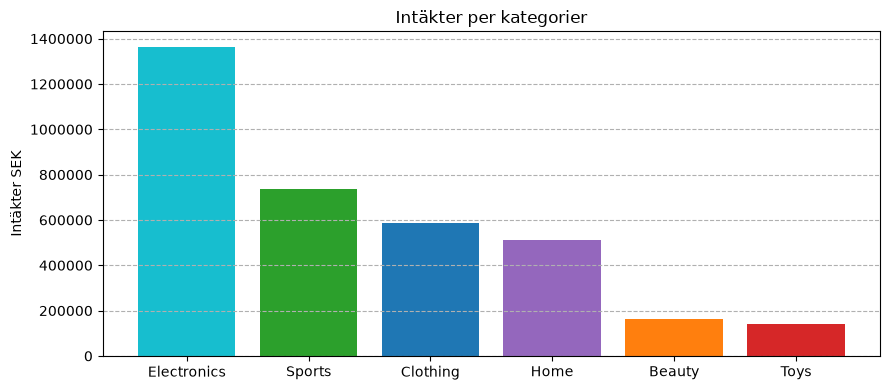

In [11]:
revenue_by_category = sorted_revenue_by_category(data, list_of_categories)
total_revenue = df["revenue"].sum()
total_units = df["units"].sum()

print(f"Total intäkt: {total_revenue:,.2f} SEK")
print(f"Antal enheter: {total_revenue:,.0f}")
print()

print_summary(revenue_by_category, "Revenue by Category:")

plot_by_category(by_category(df))


## 2. Var säljer vi?

In [12]:
revenue_by_city = sorted_revenue_for_cities(data, list_of_cities)

print_summary(revenue_by_city, "Revenue by City:")

Revenue by City:
Stockholm: 1,225,078.14 SEK
Göteborg: 859,019.65 SEK
Malmö: 567,926.32 SEK
Uppsala: 551,478.42 SEK
Västerås: 297,140.90 SEK


## 3. När säljer vi?

Monthly Revenue Breakdown:
2024-01: 664,083.32 SEK
2024-02: 548,462.03 SEK
2024-03: 487,602.00 SEK
2024-04: 580,194.83 SEK
2024-05: 632,165.16 SEK
2024-06: 590,259.89 SEK


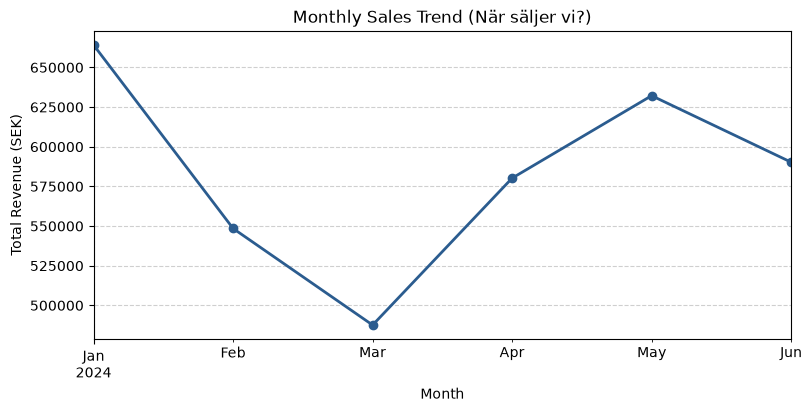

In [13]:
monthly_sales = get_monthly_sales_analysis(df)

print_summary(monthly_sales.items(), "Monthly Revenue Breakdown:")

plot_monthly_sales(monthly_sales)

## 4. Hur ser en typisk order ut?

        revenue
mean    1401.11
median  1088.69
std     1166.94
max     9192.60
min       50.00


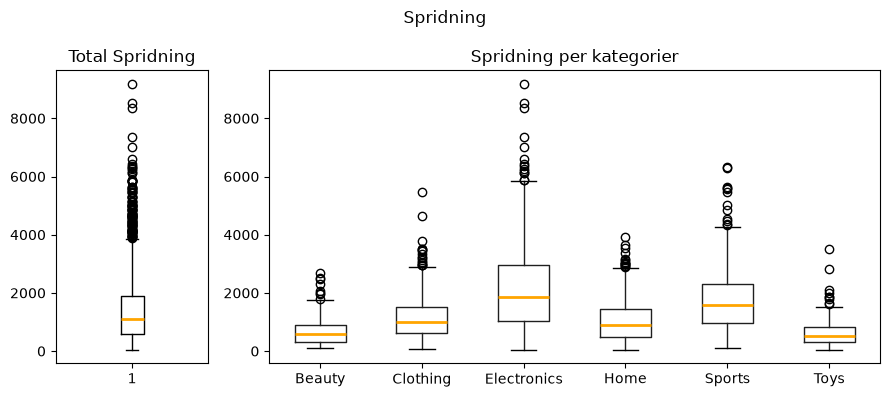

In [14]:
aov = show_avg(df)

print(aov)
plot_dispersion(df)

## 5. Topp 3 kategorier

In [15]:
top3(df)

category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Name: revenue, dtype: float64

## 6. Avvikelser

In [16]:
jan_mars = calculate_drop_increase(monthly_sales.loc["2024-02"], monthly_sales.loc["2024-03"])
mars_maj = calculate_drop_increase(monthly_sales.loc["2024-03"], monthly_sales.loc["2024-05"])

print("Jan - mars:", jan_mars)
print("Mars - maj:", mars_maj)

Jan - mars: Minskning av intäkter under perioden: -11.10%
Mars - maj: Ökning av intäkter under perioden: 29.65%


- Försäljningen visar en tydlig variation över perioden med en start **januari (664,083 SEK)** och en ny uppgång maj **(632,165 SEK)**. Den lägsta försäljningsvolymen under perioden noterades **mars (487,602.00 SEK)**.

- Intäkterna minskade **11.10%** under perioden januari till mars. Och ökade **29.65%** under mars till maj.

- AOV är **1 401 kr**, men standardavvikelsen är **1 167 kr**, vilket visar att ordervärdena varierar ganska mycket. Medianen är lägre än medelvärdet, vilket tyder på att några stora beställningar drar upp genomsnittet.

## Rekommendationer och insikter

Baserat på vår modulära dataanalys rekommenderar vi följande strategiska åtgärder:

1. **Optimera geografiskt fokus:**
   - **Stockholm** och **Göteborg** är våra mest lönsamma marknader. Vi bör prioritera lagerallokering och skala upp marknadsföringskampanjer i dessa regioner.
   - Genomföra riktade kampanjer i mindre marknader (som **Västerås**) för att öka den regionala försäljningen.

2. **Fokusera på nyckelkategorier:**
   - Inrikta marknadsföringen på de mest säljande produktkategorierna för att maximera den totala omsättningen och det genomsnittliga ordervärdet (AOV).